
別の楕円曲線を使ったECDH
楕円曲線: y^2 = x^3 + 1x + 1 mod 17
基準点 G = (0, 1)
Aliceの秘密鍵 = 5
Bobの秘密鍵 = 7

------------------------------------------------------------------------
曲線の確認
------------------------------------------------------------------------
曲線の非特異性確認
  4a^3 + 27b^2 = 4×1^3 + 27×1^2
  mod 17 = 14
  0ではないため、非特異な楕円曲線です。

------------------------------------------------------------------------
基準点の確認
------------------------------------------------------------------------
点 (0, 1) の確認
  左辺 y^2 = 1^2 ≡ 1 mod 17
  右辺 x^3 + ax + b = 0^3 + 1×0 + 1
       ≡ 1 mod 17
  曲線上にあるか: True

------------------------------------------------------------------------
曲線上の全有限点
------------------------------------------------------------------------
有限点の個数 = 17
無限遠点Oを含む曲線全体の点数 = 18
 1: (0, 1)
 2: (0, 16)
 3: (4, 1)
 4: (4, 16)
 5: (6, 6)
 6: (6, 11)
 7: (9, 5)
 8: (9, 12)
 9: (10, 5)
10: (10, 12)
11: (11, 0)
12: (13, 1)
13: (13, 16)
14: (15, 5)
15: (15, 12)
16: (16, 4)
17: (16, 13)

-------------------------

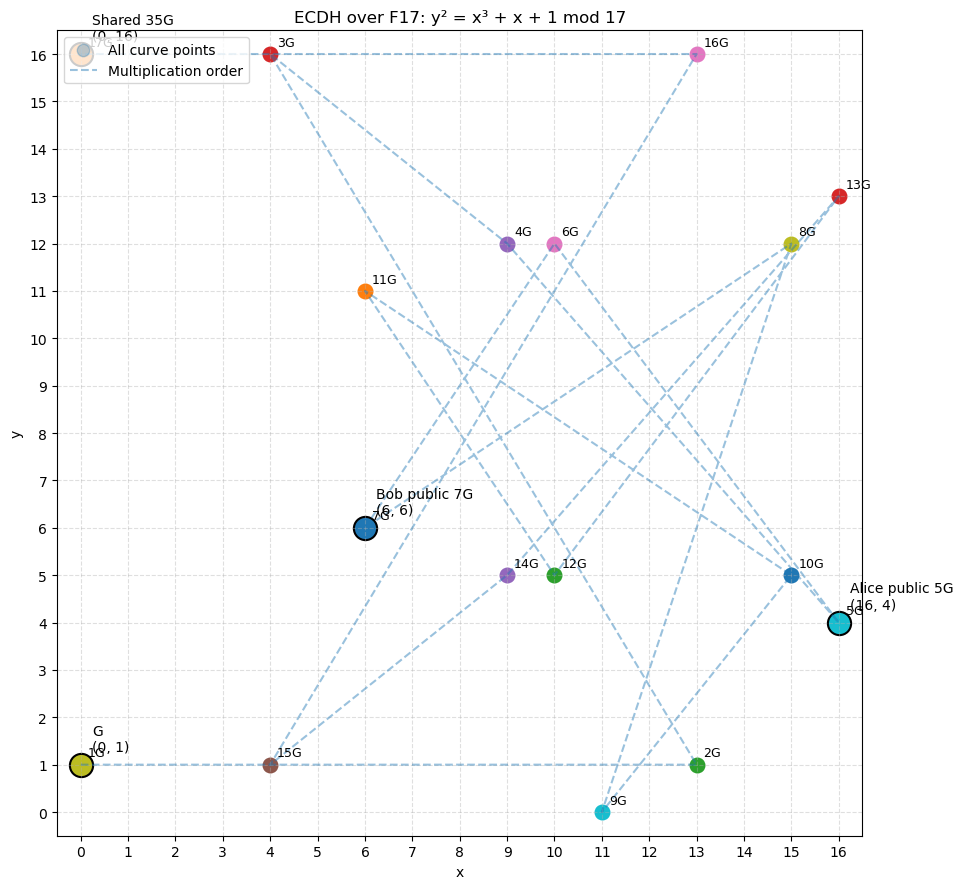


プロット画像を保存しました: ecdh_curve_x3_plus_x_plus_1.png


In [1]:
# ============================================================
# 楕円曲線暗号 ECDH 学習用プログラム
# 別の楕円曲線・途中経過・倍点表・プロット付き
#
# 楕円曲線:
#   y^2 = x^3 + x + 1 (mod 17)
#
# 基準点:
#   G = (0, 1)
#
# Aliceの秘密鍵:
#   dA = 5
#
# Bobの秘密鍵:
#   dB = 7
# ============================================================

from typing import Optional, Tuple, List
import matplotlib.pyplot as plt


# ============================================================
# 基本設定
# ============================================================

Point = Optional[Tuple[int, int]]

MODULUS = 17
CURVE_A = 1
CURVE_B = 1

BASE_POINT: Point = (0, 1)

ALICE_PRIVATE = 5
BOB_PRIVATE = 7

# True: 詳細な計算過程を表示
# False: 結果だけを表示
SHOW_DETAILS = True

# 倍点表のうち、何倍まで途中計算を詳しく表示するか
DETAILED_MULTIPLES = 4

# プロット画像の保存先
PLOT_FILE = "ecdh_curve_x3_plus_x_plus_1.png"


# ============================================================
# 表示補助
# ============================================================

def point_to_string(point: Point) -> str:
    """点を表示用文字列に変換する。"""

    if point is None:
        return "O"

    return f"({point[0]}, {point[1]})"


def print_section(title: str) -> None:
    """大見出しを表示する。"""

    print()
    print("=" * 72)
    print(title)
    print("=" * 72)


def print_subsection(title: str) -> None:
    """小見出しを表示する。"""

    print()
    print("-" * 72)
    print(title)
    print("-" * 72)


# ============================================================
# 最大公約数・逆元
# ============================================================

def extended_gcd(a: int, b: int) -> Tuple[int, int, int]:
    """
    拡張ユークリッド互除法。

    戻り値:
        gcd, x, y

    ax + by = gcd
    """

    if b == 0:
        return a, 1, 0

    gcd, x1, y1 = extended_gcd(b, a % b)

    x = y1
    y = x1 - (a // b) * y1

    return gcd, x, y


def mod_inverse(
    value: int,
    modulus: int,
    verbose: bool = False
) -> int:
    """
    valueのmodulusにおける逆元を求める。

    value × inverse ≡ 1 (mod modulus)
    """

    original_value = value
    value %= modulus

    if value == 0:
        raise ZeroDivisionError("0の逆元は存在しません。")

    gcd, x, _ = extended_gcd(value, modulus)

    if gcd != 1:
        raise ValueError(
            f"{value}と{modulus}は互いに素ではないため、"
            "逆元が存在しません。"
        )

    inverse = x % modulus

    if verbose:
        print("逆元の計算")
        print(f"  元の値           = {original_value}")
        print(f"  mod {modulus} 後 = {value}")
        print(f"  逆元             = {inverse}")
        print(
            f"  確認: {value} × {inverse}"
            f" ≡ {(value * inverse) % modulus}"
            f" mod {modulus}"
        )

    return inverse


# ============================================================
# 楕円曲線の確認
# ============================================================

def discriminant() -> int:
    """
    短いワイエルシュトラス形の判別式部分を計算する。

    4a^3 + 27b^2 mod p
    """

    return (
        4 * CURVE_A**3
        + 27 * CURVE_B**2
    ) % MODULUS


def validate_curve() -> None:
    """
    楕円曲線が特異曲線でないことを確認する。
    """

    value = discriminant()

    print("曲線の非特異性確認")
    print(
        f"  4a^3 + 27b^2"
        f" = 4×{CURVE_A}^3"
        f" + 27×{CURVE_B}^2"
    )
    print(
        f"  mod {MODULUS}"
        f" = {value}"
    )

    if value == 0:
        raise ValueError(
            "この曲線は特異曲線なので使用できません。"
        )

    print("  0ではないため、非特異な楕円曲線です。")


def is_on_curve(
    point: Point,
    verbose: bool = False
) -> bool:
    """
    点が楕円曲線上にあるか確認する。
    """

    if point is None:
        return True

    x, y = point

    left = (y * y) % MODULUS

    right = (
        x**3
        + CURVE_A * x
        + CURVE_B
    ) % MODULUS

    result = left == right

    if verbose:
        print(f"点 {point_to_string(point)} の確認")
        print(
            f"  左辺 y^2"
            f" = {y}^2"
            f" ≡ {left}"
            f" mod {MODULUS}"
        )
        print(
            f"  右辺 x^3 + ax + b"
            f" = {x}^3"
            f" + {CURVE_A}×{x}"
            f" + {CURVE_B}"
        )
        print(
            f"       ≡ {right}"
            f" mod {MODULUS}"
        )
        print(f"  曲線上にあるか: {result}")

    return result


# ============================================================
# 点の演算
# ============================================================

def point_negative(point: Point) -> Point:
    """
    点Pの逆元-Pを求める。

    -(x, y) = (x, -y mod p)
    """

    if point is None:
        return None

    x, y = point

    return x, (-y) % MODULUS


def point_add(
    point1: Point,
    point2: Point,
    verbose: bool = False,
    label: str = ""
) -> Point:
    """
    楕円曲線上の2点を加算する。
    """

    if verbose:
        print()
        print("点の加算")
        if label:
            print(f"  内容: {label}")

        print(f"  P = {point_to_string(point1)}")
        print(f"  Q = {point_to_string(point2)}")

    # O + Q = Q
    if point1 is None:
        if verbose:
            print("  Pは無限遠点Oです。")
            print(
                f"  O + Q = Q"
                f" = {point_to_string(point2)}"
            )

        return point2

    # P + O = P
    if point2 is None:
        if verbose:
            print("  Qは無限遠点Oです。")
            print(
                f"  P + O = P"
                f" = {point_to_string(point1)}"
            )

        return point1

    x1, y1 = point1
    x2, y2 = point2

    # P + (-P) = O
    if x1 == x2 and (y1 + y2) % MODULUS == 0:
        if verbose:
            print("  PとQは互いに逆元です。")
            print(
                f"  y1 + y2"
                f" = {y1} + {y2}"
                f" = {y1 + y2}"
            )
            print(
                f"  {y1 + y2}"
                f" ≡ 0 mod {MODULUS}"
            )
            print("  よって P + Q = O")

        return None

    # --------------------------------------------------------
    # 同じ点を加える場合
    # --------------------------------------------------------

    if point1 == point2:
        calculation_type = "倍点計算"

        numerator_raw = (
            3 * x1 * x1
            + CURVE_A
        )

        denominator_raw = 2 * y1

        numerator = numerator_raw % MODULUS
        denominator = denominator_raw % MODULUS

        if verbose:
            print(f"  種類: {calculation_type}")
            print()
            print("傾きの分子")
            print(
                f"  3x1^2 + a"
                f" = 3×{x1}^2"
                f" + {CURVE_A}"
            )
            print(
                f"             = {numerator_raw}"
            )
            print(
                f"             ≡ {numerator}"
                f" mod {MODULUS}"
            )

            print()
            print("傾きの分母")
            print(
                f"  2y1"
                f" = 2×{y1}"
                f" = {denominator_raw}"
            )
            print(
                f"      ≡ {denominator}"
                f" mod {MODULUS}"
            )

    # --------------------------------------------------------
    # 異なる2点を加える場合
    # --------------------------------------------------------

    else:
        calculation_type = "異なる2点の加算"

        numerator_raw = y2 - y1
        denominator_raw = x2 - x1

        numerator = numerator_raw % MODULUS
        denominator = denominator_raw % MODULUS

        if verbose:
            print(f"  種類: {calculation_type}")

            print()
            print("傾きの分子")
            print(
                f"  y2 - y1"
                f" = {y2} - {y1}"
                f" = {numerator_raw}"
            )
            print(
                f"  {numerator_raw}"
                f" ≡ {numerator}"
                f" mod {MODULUS}"
            )

            print()
            print("傾きの分母")
            print(
                f"  x2 - x1"
                f" = {x2} - {x1}"
                f" = {denominator_raw}"
            )
            print(
                f"  {denominator_raw}"
                f" ≡ {denominator}"
                f" mod {MODULUS}"
            )

    inverse = mod_inverse(
        denominator,
        MODULUS,
        verbose=verbose
    )

    slope_raw = numerator * inverse
    slope = slope_raw % MODULUS

    if verbose:
        print()
        print("傾きλの計算")
        print(
            f"  λ = {numerator}"
            f" × {inverse}"
            f" mod {MODULUS}"
        )
        print(
            f"    = {slope_raw}"
            f" mod {MODULUS}"
        )
        print(f"    = {slope}")

    x3_raw = slope * slope - x1 - x2
    x3 = x3_raw % MODULUS

    if verbose:
        print()
        print("x3の計算")
        print(
            f"  x3 = λ^2 - x1 - x2"
            f" mod {MODULUS}"
        )
        print(
            f"     = {slope}^2"
            f" - {x1}"
            f" - {x2}"
        )
        print(
            f"     = {x3_raw}"
            f" ≡ {x3}"
            f" mod {MODULUS}"
        )

    y3_raw = slope * (x1 - x3) - y1
    y3 = y3_raw % MODULUS

    if verbose:
        print()
        print("y3の計算")
        print(
            f"  y3 = λ(x1-x3)-y1"
            f" mod {MODULUS}"
        )
        print(
            f"     = {slope}"
            f"×({x1}-{x3})"
            f"-{y1}"
        )
        print(
            f"     = {y3_raw}"
            f" ≡ {y3}"
            f" mod {MODULUS}"
        )

    result = x3, y3

    if not is_on_curve(result):
        raise ValueError(
            f"計算結果{result}は曲線上にありません。"
        )

    if verbose:
        print()
        print(
            f"結果: "
            f"{point_to_string(point1)}"
            f" + "
            f"{point_to_string(point2)}"
            f" = "
            f"{point_to_string(result)}"
        )

    return result


# ============================================================
# スカラー倍算
# ============================================================

def scalar_multiply(
    scalar: int,
    point: Point,
    verbose: bool = False,
    label: str = ""
) -> Point:
    """
    倍加加算法でscalar × pointを求める。
    """

    if scalar < 0:
        raise ValueError(
            "負のスカラーには対応していません。"
        )

    if point is not None and not is_on_curve(point):
        raise ValueError(
            f"点{point}は曲線上にありません。"
        )

    if verbose:
        print_subsection(
            label
            if label
            else (
                f"{scalar}"
                f" × "
                f"{point_to_string(point)}"
            )
        )

        print(f"スカラー       = {scalar}")
        print(f"2進数          = {scalar:b}")
        print(
            f"計算対象の点   = "
            f"{point_to_string(point)}"
        )

    original_scalar = scalar

    result: Point = None
    addend = point

    step = 1

    while scalar > 0:
        current_bit = scalar & 1

        if verbose:
            print()
            print("#" * 72)
            print(f"ステップ {step}")
            print("#" * 72)
            print(f"現在の値       = {scalar}")
            print(f"現在の2進数    = {scalar:b}")
            print(f"最下位ビット   = {current_bit}")
            print(
                f"result          = "
                f"{point_to_string(result)}"
            )
            print(
                f"addend          = "
                f"{point_to_string(addend)}"
            )

        # 最下位ビットが1の場合
        if current_bit == 1:
            if verbose:
                print()
                print(
                    "最下位ビットが1なので、"
                    "resultにaddendを加えます。"
                )

            result = point_add(
                result,
                addend,
                verbose=verbose,
                label="result + addend"
            )

            if verbose:
                print(
                    f"加算後のresult = "
                    f"{point_to_string(result)}"
                )

        else:
            if verbose:
                print()
                print(
                    "最下位ビットが0なので、"
                    "resultへの加算は行いません。"
                )

        # 次の桁のためにaddendを2倍
        if verbose:
            print()
            print("addendを2倍します。")

        addend = point_add(
            addend,
            addend,
            verbose=verbose,
            label="addend + addend"
        )

        if verbose:
            print(
                f"倍点後のaddend = "
                f"{point_to_string(addend)}"
            )

        old_scalar = scalar
        scalar >>= 1

        if verbose:
            print()
            print(
                f"右シフト: "
                f"{old_scalar:b}"
                f"₂ → {scalar:b}"
                f"₂"
            )

        step += 1

    if verbose:
        print()
        print("*" * 72)
        print(
            f"最終結果: "
            f"{original_scalar}"
            f" × "
            f"{point_to_string(point)}"
            f" = "
            f"{point_to_string(result)}"
        )
        print("*" * 72)

    return result


# ============================================================
# 曲線上の全点
# ============================================================

def get_all_curve_points() -> List[Tuple[int, int]]:
    """
    有限体上の楕円曲線の全有限点を列挙する。
    """

    points: List[Tuple[int, int]] = []

    for x in range(MODULUS):
        right = (
            x**3
            + CURVE_A * x
            + CURVE_B
        ) % MODULUS

        for y in range(MODULUS):
            left = (y * y) % MODULUS

            if left == right:
                points.append((x, y))

    return points


def print_curve_points() -> None:
    """
    曲線上の全有限点を表示する。
    """

    points = get_all_curve_points()

    print_subsection("曲線上の全有限点")

    print(
        f"有限点の個数 = {len(points)}"
    )
    print(
        "無限遠点Oを含む曲線全体の点数"
        f" = {len(points) + 1}"
    )

    for index, point in enumerate(points, start=1):
        print(
            f"{index:2d}: "
            f"{point_to_string(point)}"
        )


# ============================================================
# 点の位数と倍点表
# ============================================================

def calculate_point_order(
    point: Point,
    maximum: int = 1000
) -> int:
    """
    点の位数を逐次加算で求める。
    """

    current: Point = None

    for scalar in range(1, maximum + 1):
        current = point_add(
            current,
            point,
            verbose=False
        )

        if current is None:
            return scalar

    raise ValueError(
        f"位数が{maximum}以内で見つかりません。"
    )


def create_multiple_table(
    point: Point,
    order: int,
    detailed_until: int = 0
) -> List[Point]:
    """
    G、2G、3G、...、order×Gを逐次計算する。
    """

    print_subsection("倍点表")

    multiples: List[Point] = []
    current: Point = None

    for scalar in range(1, order + 1):
        verbose = (
            SHOW_DETAILS
            and scalar <= detailed_until
        )

        if verbose:
            print_subsection(
                f"{scalar}Gの逐次計算"
            )

        current = point_add(
            current,
            point,
            verbose=verbose,
            label=(
                f"{scalar}G"
                f" = "
                f"{scalar - 1}G"
                f" + G"
            )
        )

        multiples.append(current)

        print(
            f"{scalar:2d}G"
            f" = "
            f"{point_to_string(current)}"
        )

    return multiples


# ============================================================
# プロット
# ============================================================

def plot_curve(
    multiples: List[Point],
    alice_public: Point,
    bob_public: Point,
    shared_point: Point
) -> None:
    """
    曲線上の全点、倍点、公開鍵、共有点をプロットする。
    """

    all_points = get_all_curve_points()

    figure, axis = plt.subplots(
        figsize=(11, 9)
    )

    # 全ての有限点
    all_x = [point[0] for point in all_points]
    all_y = [point[1] for point in all_points]

    axis.scatter(
        all_x,
        all_y,
        s=80,
        alpha=0.30,
        label="All curve points"
    )

    # 倍点を順番に線で結ぶ
    finite_multiples = [
        point
        for point in multiples
        if point is not None
    ]

    multiple_x = [
        point[0]
        for point in finite_multiples
    ]

    multiple_y = [
        point[1]
        for point in finite_multiples
    ]

    axis.plot(
        multiple_x,
        multiple_y,
        linestyle="--",
        alpha=0.45,
        label="Multiplication order"
    )

    # 各倍点
    for scalar, point in enumerate(
        multiples,
        start=1
    ):
        if point is None:
            continue

        x, y = point

        axis.scatter(
            x,
            y,
            s=110
        )

        axis.annotate(
            f"{scalar}G",
            xy=(x, y),
            xytext=(5, 6),
            textcoords="offset points",
            fontsize=9
        )

    # 特別な点を強調
    special_points = [
        ("G", BASE_POINT),
        ("Alice public 5G", alice_public),
        ("Bob public 7G", bob_public),
        ("Shared 35G", shared_point),
    ]

    for label, point in special_points:
        if point is None:
            continue

        x, y = point

        axis.scatter(
            x,
            y,
            s=280,
            edgecolors="black",
            linewidths=1.5
        )

        axis.annotate(
            f"{label}\n{point_to_string(point)}",
            xy=(x, y),
            xytext=(8, 10),
            textcoords="offset points",
            fontsize=10
        )

    axis.set_title(
        "ECDH over F17: "
        "y² = x³ + x + 1 mod 17"
    )

    axis.set_xlabel("x")
    axis.set_ylabel("y")

    axis.set_xticks(range(MODULUS))
    axis.set_yticks(range(MODULUS))

    axis.set_xlim(
        -0.5,
        MODULUS - 0.5
    )

    axis.set_ylim(
        -0.5,
        MODULUS - 0.5
    )

    axis.set_aspect(
        "equal",
        adjustable="box"
    )

    axis.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    axis.legend(
        loc="upper left"
    )

    figure.tight_layout()

    figure.savefig(
        PLOT_FILE,
        dpi=180
    )

    plt.show()
    plt.close(figure)

    print()
    print(
        f"プロット画像を保存しました: "
        f"{PLOT_FILE}"
    )


# ============================================================
# メイン処理
# ============================================================

def main() -> None:
    print_section(
        "別の楕円曲線を使ったECDH"
    )

    print(
        "楕円曲線:"
        f" y^2 = x^3"
        f" + {CURVE_A}x"
        f" + {CURVE_B}"
        f" mod {MODULUS}"
    )

    print(
        f"基準点 G"
        f" = {point_to_string(BASE_POINT)}"
    )

    print(
        f"Aliceの秘密鍵"
        f" = {ALICE_PRIVATE}"
    )

    print(
        f"Bobの秘密鍵"
        f" = {BOB_PRIVATE}"
    )

    # 曲線の確認
    print_subsection("曲線の確認")
    validate_curve()

    # 基準点の確認
    print_subsection("基準点の確認")

    if not is_on_curve(
        BASE_POINT,
        verbose=True
    ):
        raise ValueError(
            "基準点Gは曲線上にありません。"
        )

    # 全点表示
    print_curve_points()

    # 位数
    print_subsection("基準点の位数")

    order = calculate_point_order(
        BASE_POINT
    )

    print(
        f"Gの位数"
        f" = {order}"
    )

    # 倍点表
    multiples = create_multiple_table(
        BASE_POINT,
        order,
        detailed_until=DETAILED_MULTIPLES
    )

    # Aliceの公開鍵
    print_section("Aliceの公開鍵")

    alice_public = scalar_multiply(
        ALICE_PRIVATE,
        BASE_POINT,
        verbose=SHOW_DETAILS,
        label=(
            "Aliceの公開鍵"
            " QA = dA × G"
        )
    )

    print()
    print(
        f"Aliceの秘密鍵 dA"
        f" = {ALICE_PRIVATE}"
    )

    print(
        f"Aliceの公開鍵 QA"
        f" = {point_to_string(alice_public)}"
    )

    # Bobの公開鍵
    print_section("Bobの公開鍵")

    bob_public = scalar_multiply(
        BOB_PRIVATE,
        BASE_POINT,
        verbose=SHOW_DETAILS,
        label=(
            "Bobの公開鍵"
            " QB = dB × G"
        )
    )

    print()
    print(
        f"Bobの秘密鍵 dB"
        f" = {BOB_PRIVATE}"
    )

    print(
        f"Bobの公開鍵 QB"
        f" = {point_to_string(bob_public)}"
    )

    # Alice側共有点
    print_section("Alice側の共有点")

    alice_shared = scalar_multiply(
        ALICE_PRIVATE,
        bob_public,
        verbose=SHOW_DETAILS,
        label=(
            "Aliceの共有点"
            " SA = dA × QB"
        )
    )

    # Bob側共有点
    print_section("Bob側の共有点")

    bob_shared = scalar_multiply(
        BOB_PRIVATE,
        alice_public,
        verbose=SHOW_DETAILS,
        label=(
            "Bobの共有点"
            " SB = dB × QA"
        )
    )

    # 最終結果
    print_section("ECDHの結果")

    print(
        f"Aliceの公開鍵"
        f" = {point_to_string(alice_public)}"
    )

    print(
        f"Bobの公開鍵"
        f"   = {point_to_string(bob_public)}"
    )

    print()

    print(
        f"Aliceの共有点"
        f" = {point_to_string(alice_shared)}"
    )

    print(
        f"Bobの共有点"
        f"   = {point_to_string(bob_shared)}"
    )

    if alice_shared != bob_shared:
        raise ValueError(
            "AliceとBobの共有点が一致しません。"
        )

    print()
    print("共有点は一致しました。")

    if alice_shared is not None:
        shared_x, shared_y = alice_shared

        print(
            f"共有点 S"
            f" = ({shared_x}, {shared_y})"
        )

        print(
            f"共有点のx座標"
            f" = {shared_x}"
        )

        print(
            f"共有点のy座標"
            f" = {shared_y}"
        )

    # 理論的な確認
    product = (
        ALICE_PRIVATE
        * BOB_PRIVATE
    )

    reduced_product = product % order

    print()
    print("スカラーによる確認")

    print(
        f"dA × dB"
        f" = {ALICE_PRIVATE}"
        f" × {BOB_PRIVATE}"
        f" = {product}"
    )

    print(
        f"{product}"
        f" mod {order}"
        f" = {reduced_product}"
    )

    verification = scalar_multiply(
        reduced_product,
        BASE_POINT,
        verbose=False
    )

    print(
        f"{product}G"
        f" = {reduced_product}G"
        f" = {point_to_string(verification)}"
    )

    # プロット
    print_section("プロット")

    plot_curve(
        multiples=multiples[:-1],
        alice_public=alice_public,
        bob_public=bob_public,
        shared_point=alice_shared
    )


if __name__ == "__main__":
    main()